# PesaPap Fintech Growth Analytics
**Tools:** Python, pandas, SQLite, SQL, NumPy, SciPy and Matplotlib.

**Objective:** Evaluate transaction performance, customer value, retention and an onboarding experiment to guide growth decisions.

**Data:** Synthetic dataset generated using the supplied seed 77.


In [1]:
from pathlib import Path
import sqlite3
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ROOT = Path.cwd()
print("Project directory:", ROOT)


Project directory: C:\Users\HPF\plp-da-a7-pesapap-growth-analytics


## 1. Load data and build the SQLite database

The database contains three tables. `users.user_id`, `transactions.txn_id`, and `experiment.user_id` are primary keys. The transaction and experiment tables reference `users.user_id`.


In [2]:
users = pd.read_csv("users.csv", parse_dates=["signup_date"])
transactions = pd.read_csv("transactions.csv", parse_dates=["txn_date"])
experiment = pd.read_csv("experiment.csv")

assert users["user_id"].is_unique
assert transactions["txn_id"].is_unique
assert experiment["user_id"].is_unique
assert set(transactions["user_id"]).issubset(set(users["user_id"]))
assert set(experiment["user_id"]) == set(users["user_id"])

db_path = ROOT / "pesapap.db"
if db_path.exists():
    db_path.unlink()

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    users.to_sql("users", conn, index=False, if_exists="replace")
    transactions.to_sql("transactions", conn, index=False, if_exists="replace")
    experiment.to_sql("experiment", conn, index=False, if_exists="replace")

    conn.executescript("""
    CREATE UNIQUE INDEX idx_users_user_id ON users(user_id);
    CREATE UNIQUE INDEX idx_transactions_txn_id ON transactions(txn_id);
    CREATE INDEX idx_transactions_user_id ON transactions(user_id);
    CREATE UNIQUE INDEX idx_experiment_user_id ON experiment(user_id);
    """)

print("Database created:", db_path)
print("Users:", len(users), "| Transactions:", len(transactions),
      "| Experiment participants:", len(experiment))
display(pd.DataFrame({
    "table": ["users", "transactions", "experiment"],
    "rows": [len(users), len(transactions), len(experiment)],
    "primary_key": ["user_id", "txn_id", "user_id"]
}))


Database created: C:\Users\HPF\plp-da-a7-pesapap-growth-analytics\pesapap.db
Users: 3000 | Transactions: 12000 | Experiment participants: 3000


,table,rows,primary_key
0,users,3000,user_id
1,transactions,12000,txn_id
2,experiment,3000,user_id


## 2. SQL validation and questions A–H

Each query is loaded from `sql/queries.sql` and executed using `pd.read_sql_query`. The validation count identifies transactions dated before a user's signup date.


In [3]:
sql_text = Path("sql/queries.sql").read_text(encoding="utf-8-sig")
statements = [
    statement.strip()
    for statement in re.split(r";\s*(?=\n|$)", sql_text)
    if statement.strip() and "SELECT" in statement.upper()
]

sql_results = {}
with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    for i, statement in enumerate(statements, start=1):
        label_match = re.search(
            r"--\s*(DATA VALIDATION|QUESTION [A-H]):([^\n]*)",
            statement,
            flags=re.IGNORECASE
        )
        label = (
            f"{label_match.group(1)}: {label_match.group(2).strip()}"
            if label_match else f"SQL query {i}"
        )
        result = pd.read_sql_query(statement, conn)
        sql_results[label] = result
        print("\n" + label)
        display(result)

assert len(sql_results) == 9, f"Expected 9 SQL results, got {len(sql_results)}"
print("PASS: validation plus SQL questions A-H executed.")



DATA VALIDATION: How many transactions occurred before the user's signup date?


,transactions_before_signup
0,3737



QUESTION A: What is the total transaction value and transaction count by product?


,product,transaction_count,total_value_kes
0,Send Money,4161,"5,639,308.000"
1,Airtime,3662,"4,708,104.000"
2,Bill Pay,2388,"3,224,392.000"
3,Merchant Pay,1789,"2,407,505.000"



QUESTION B: Which five counties have the highest transaction value?


...


QUESTION G: How many users fall into each lifetime transaction-value tier?


,value_tier,user_count,total_value_kes
0,High,345,"4,658,992.000"
1,Medium,1317,"8,360,138.000"
2,Low,1338,"2,960,179.000"



QUESTION H: How does the number of monthly active users change month over month?


,month,active_users,previous_active_users,change_in_users,mom_growth_pct
0,2026-01,1055,NaN,NaN,NaN
1,2026-02,1596,"1,055.000",541.000,51.280
2,2026-03,1649,"1,596.000",53.000,3.320
3,2026-04,1704,"1,649.000",55.000,3.340
4,2026-05,1690,"1,704.000",-14.000,-0.820
5,2026-06,907,"1,690.000",-783.000,-46.330


PASS: validation plus SQL questions A-H executed.


### Data validation interpretation

Transactions dated before signup are temporally inconsistent with normal user activity. Because the supplied generator samples signup and transaction dates independently, these rows are expected in this synthetic dataset. Keep the raw records for auditability, flag them, and exclude them from lifecycle or post-signup measures where appropriate. Report the count rather than silently changing the source data.


In [4]:
pre_signup_count = int(
    ((transactions.merge(users[["user_id", "signup_date"]], on="user_id"))
     .eval("txn_date < signup_date")).sum()
)
print(f"Transactions before signup: {pre_signup_count:,}")
print(f"Share of transactions: {pre_signup_count / len(transactions):.2%}")


Transactions before signup: 3,737
Share of transactions: 31.14%


## 3. KPI scorecard and metric dictionary

Transaction value is the sum of transaction amounts. Active users are distinct users with at least one transaction during the relevant month. Month-over-month growth compares the current month with the previous calendar month.


In [5]:
total_value = transactions["amount"].sum()
transaction_count = transactions["txn_id"].nunique()
active_users_all_period = transactions["user_id"].nunique()
average_transaction_value = transactions["amount"].mean()
average_transactions_per_active_user = (
    transaction_count / active_users_all_period
    if active_users_all_period else np.nan
)

monthly = (
    transactions.assign(month=transactions["txn_date"].dt.to_period("M").astype(str))
    .groupby("month")
    .agg(
        transaction_value=("amount", "sum"),
        transaction_count=("txn_id", "nunique"),
        active_users=("user_id", "nunique")
    )
    .reset_index()
    .sort_values("month")
)
monthly["mom_growth_pct"] = monthly["transaction_value"].pct_change() * 100

kpis = pd.DataFrame([
    ["Total transaction value", total_value, "KES"],
    ["Number of transactions", transaction_count, "transactions"],
    ["Distinct active users", active_users_all_period, "users"],
    ["Average transaction value", average_transaction_value, "KES/transaction"],
    ["Average transactions per active user", average_transactions_per_active_user, "transactions/user"]
], columns=["metric", "value", "unit"])

metric_dictionary = pd.DataFrame([
    ["Total transaction value", "Sum of all transaction amounts in the analysis period.", "SUM(amount)"],
    ["Number of transactions", "Count of distinct transaction IDs in the analysis period.", "COUNT(DISTINCT txn_id)"],
    ["Active users", "Distinct users with at least one transaction in the specified period.", "COUNT(DISTINCT user_id)"],
    ["Average transaction value", "Mean amount per transaction.", "SUM(amount) / COUNT(txn_id)"],
    ["Transactions per active user", "Transactions divided by distinct users who transacted in the period.", "COUNT(txn_id) / COUNT(DISTINCT user_id)"],
    ["MoM transaction-value growth", "Percentage change in transaction value from the previous calendar month.", "(current month value - previous month value) / previous month value * 100"]
], columns=["name", "definition", "calculation"])

print("KPI SCORECARD")
display(kpis)
print("MONTHLY SCORECARD")
display(monthly)
print("METRIC DICTIONARY")
display(metric_dictionary)


KPI SCORECARD


,metric,value,unit
0,Total transaction value,"15,979,309.000",KES
1,Number of transactions,"12,000.000",transactions
2,Distinct active users,"2,943.000",users
3,Average transaction value,"1,331.609",KES/transaction
4,Average transactions per active user,4.077,transactions/user


MONTHLY SCORECARD


,month,transaction_value,transaction_count,active_users,mom_growth_pct
0,2026-01,"1,733,121.000",1308,1055,NaN
1,2026-02,"2,993,105.000",2272,1596,72.700
2,2026-03,"3,199,125.000",2394,1649,6.883
3,2026-04,"3,262,447.000",2470,1704,1.979
4,2026-05,"3,365,002.000",2475,1690,3.143
5,2026-06,"1,426,509.000",1081,907,-57.607


METRIC DICTIONARY


,name,definition,calculation
0,Total transaction value,Sum of all transaction amounts in the analysis...,SUM(amount)
1,Number of transactions,Count of distinct transaction IDs in the analy...,COUNT(DISTINCT txn_id)
2,Active users,Distinct users with at least one transaction i...,COUNT(DISTINCT user_id)
3,Average transaction value,Mean amount per transaction.,SUM(amount) / COUNT(txn_id)
4,Transactions per active user,Transactions divided by distinct users who tra...,COUNT(txn_id) / COUNT(DISTINCT user_id)
5,MoM transaction-value growth,Percentage change in transaction value from th...,(current month value - previous month value) /...


## 4. RFM customer segmentation

Recency is measured in days since a user's most recent transaction, relative to the latest transaction date in the dataset. Frequency is the number of transactions; monetary value is the total transaction value. Users without transactions remain in the analysis and are assigned zero frequency and monetary value.


In [6]:
reference_date = transactions["txn_date"].max() + pd.Timedelta(days=1)

rfm = (
    transactions.groupby("user_id")
    .agg(
        last_transaction=("txn_date", "max"),
        frequency=("txn_id", "nunique"),
        monetary=("amount", "sum")
    )
    .reindex(users["user_id"])
)
rfm.index.name = "user_id"
rfm["recency_days"] = (reference_date - rfm["last_transaction"]).dt.days
rfm["frequency"] = rfm["frequency"].fillna(0).astype(int)
rfm["monetary"] = rfm["monetary"].fillna(0)
rfm["recency_days"] = rfm["recency_days"].fillna(
    (reference_date - users.set_index("user_id")["signup_date"]).dt.days
)
rfm["recency_days"] = rfm["recency_days"].astype(int)

def make_score(series, higher_is_better=True):
    if series.nunique() <= 1:
        return pd.Series(3, index=series.index, dtype=int)
    ranks = series.rank(method="average", ascending=not higher_is_better)
    return pd.qcut(ranks, q=4, labels=[1, 2, 3, 4]).astype(int)

rfm["R_score"] = make_score(rfm["recency_days"], higher_is_better=False)
rfm["F_score"] = make_score(rfm["frequency"])
rfm["M_score"] = make_score(rfm["monetary"])

def assign_segment(row):
    if row["frequency"] == 0:
        return "No Transactions"
    if row["R_score"] >= 3 and row["F_score"] >= 3 and row["M_score"] >= 3:
        return "Champions"
    if row["F_score"] >= 3 and row["M_score"] >= 3:
        return "Loyal High Value"
    if row["R_score"] >= 3 and row["F_score"] <= 2:
        return "Recent / Developing"
    if row["R_score"] <= 2 and row["F_score"] >= 3:
        return "At Risk High Value"
    return "Needs Nurturing"

rfm["segment"] = rfm.apply(assign_segment, axis=1)

segment_summary = (
    rfm.groupby("segment", observed=True)
    .agg(
        users=("frequency", "size"),
        transaction_value=("monetary", "sum"),
        average_value_per_user=("monetary", "mean")
    )
    .reset_index()
)
segment_summary["user_share_pct"] = segment_summary["users"] / len(rfm) * 100
segment_summary["value_share_pct"] = (
    segment_summary["transaction_value"] / total_value * 100
)
display(segment_summary.sort_values("transaction_value", ascending=False))

first_target = segment_summary[
    segment_summary["segment"].isin(["At Risk High Value", "Loyal High Value", "Champions"])
].sort_values("transaction_value", ascending=False)

print("Targeting recommendation: investigate high-value customers first.")
print("Use retention offers for At Risk High Value users and loyalty benefits for active high-value users.")


,segment,users,transaction_value,average_value_per_user,user_share_pct,value_share_pct
3,Needs Nurturing,1230,"8,936,509.000","7,265.454",41.000,55.926
5,Recent / Developing,624,"4,183,452.000","6,704.250",20.800,26.180
1,Champions,640,"1,339,271.000","2,092.611",21.333,8.381
2,Loyal High Value,346,"792,899.000","2,291.616",11.533,4.962
0,At Risk High Value,103,"727,178.000","7,059.981",3.433,4.551
4,No Transactions,57,0.000,0.000,1.900,0.000


Targeting recommendation: investigate high-value customers first.
Use retention offers for At Risk High Value users and loyalty benefits for active high-value users.


## 5. Monthly cohort retention

Cohort month is each user's signup month. Activity month is the month of a transaction. Retention is the share of users in a signup cohort who transacted in each month. Cells after the latest available observation are marked `Incomplete` rather than interpreted as zero retention.


Retention percentages; future/unobserved cohort cells are flagged.

,-3,-2,-1,0,1,2,3,4,5
cohort_month,,,,,,,,,
2026-01,0.000,0.000,0.000,33.000,53.700,55.900,58.300,56.000,33.500
2026-02,0.000,0.000,36.800,52.100,54.900,54.600,59.000,28.700,Incomplete
2026-03,0.000,36.100,52.600,54.400,55.400,56.900,30.200,Incomplete,Incomplete
2026-04,34.900,54.300,54.700,58.500,53.700,28.400,Incomplete,Incomplete,Incomplete


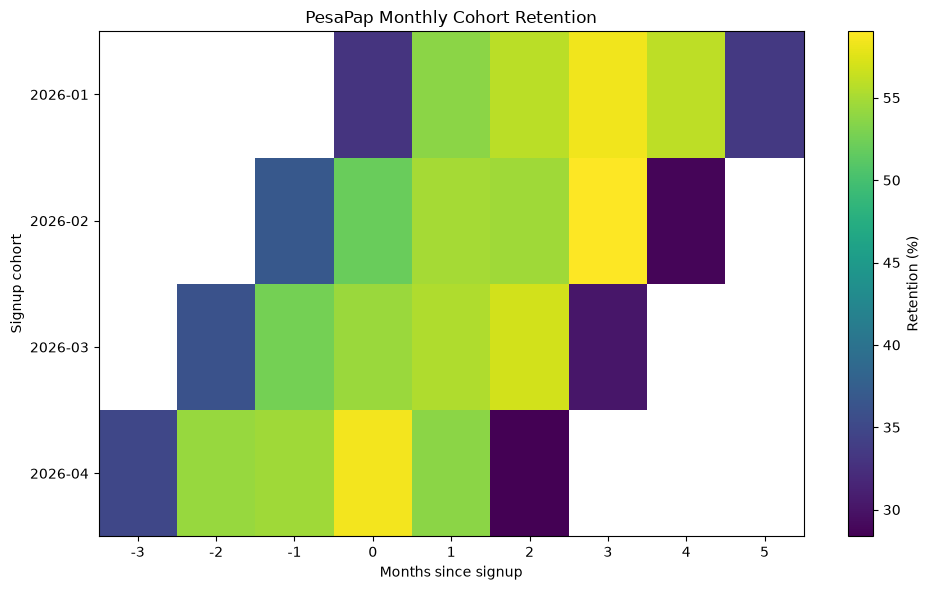

Interpretation: compare only observed cells; incomplete cells are not evidence of churn.


In [7]:
cohort_source = transactions.merge(
    users[["user_id", "signup_date"]], on="user_id", how="left"
)
cohort_source["cohort_month"] = cohort_source["signup_date"].dt.to_period("M")
cohort_source["activity_month"] = cohort_source["txn_date"].dt.to_period("M")
cohort_source["cohort_age"] = (
    (cohort_source["activity_month"].dt.year - cohort_source["cohort_month"].dt.year) * 12
    + cohort_source["activity_month"].dt.month
    - cohort_source["cohort_month"].dt.month
)

cohort_sizes = users.assign(
    cohort_month=users["signup_date"].dt.to_period("M")
).groupby("cohort_month")["user_id"].nunique()

cohort_activity = cohort_source.groupby(
    ["cohort_month", "cohort_age"]
)["user_id"].nunique().unstack()

retention = cohort_activity.div(cohort_sizes, axis=0) * 100
retention.index = retention.index.astype(str)
retention.columns = [int(c) for c in retention.columns]

latest_activity_month = transactions["txn_date"].dt.to_period("M").max()
cohort_month_periods = users["signup_date"].dt.to_period("M")
retention_display = retention.copy().astype(object)

for cohort_label in retention.index:
    cohort_period = pd.Period(cohort_label, freq="M")
    for age in retention.columns:
        observed_month = cohort_period + int(age)
        if observed_month > latest_activity_month:
            retention_display.loc[cohort_label, age] = "Incomplete"
        elif pd.isna(retention.loc[cohort_label, age]):
            retention_display.loc[cohort_label, age] = 0.0
        else:
            retention_display.loc[cohort_label, age] = round(
                float(retention.loc[cohort_label, age]), 1
            )

print("Retention percentages; future/unobserved cohort cells are flagged.")
display(retention_display)

plt.figure(figsize=(10, 6))
masked_retention = retention.astype(float)
for cohort_label in retention.index:
    cohort_period = pd.Period(cohort_label, freq="M")
    for age in retention.columns:
        if cohort_period + int(age) > latest_activity_month:
            masked_retention.loc[cohort_label, age] = np.nan
plt.imshow(masked_retention, aspect="auto", interpolation="nearest")
plt.colorbar(label="Retention (%)")
plt.xticks(range(len(retention.columns)), retention.columns)
plt.yticks(range(len(retention.index)), retention.index)
plt.xlabel("Months since signup")
plt.ylabel("Signup cohort")
plt.title("PesaPap Monthly Cohort Retention")
plt.tight_layout()
plt.show()

print("Interpretation: compare only observed cells; incomplete cells are not evidence of churn.")


## 6. Onboarding A/B experiment

**H₀:** The conversion rates for groups A and B are equal.

**H₁:** The conversion rates differ. The test below uses a two-sided chi-square test and a two-sided 95% confidence interval for the absolute conversion-rate difference (B minus A).


In [8]:
exp = experiment.copy()
exp["converted"] = exp["converted"].astype(int)

group_summary = exp.groupby("group").agg(
    assigned_users=("user_id", "nunique"),
    conversions=("converted", "sum")
)
group_summary["conversion_rate"] = (
    group_summary["conversions"] / group_summary["assigned_users"]
)
display(group_summary)

assert set(group_summary.index) == {"A", "B"}
n_a = int(group_summary.loc["A", "assigned_users"])
n_b = int(group_summary.loc["B", "assigned_users"])
x_a = int(group_summary.loc["A", "conversions"])
x_b = int(group_summary.loc["B", "conversions"])
p_a = x_a / n_a
p_b = x_b / n_b
absolute_lift = p_b - p_a
relative_lift = (absolute_lift / p_a) * 100 if p_a else np.nan

balance_difference = abs(n_a - n_b)
balance_pct = balance_difference / ((n_a + n_b) / 2) * 100
print(f"Group balance: A={n_a:,}; B={n_b:,}; size difference={balance_difference:,} ({balance_pct:.2f}% of average group size)")
print(f"Group A conversion: {p_a:.2%}")
print(f"Group B conversion: {p_b:.2%}")
print(f"Absolute lift (B - A): {absolute_lift:.2%} ({absolute_lift * 100:.2f} percentage points)")
print(f"Relative lift: {relative_lift:.2f}%")

contingency = np.array([
    [x_a, n_a - x_a],
    [x_b, n_b - x_b]
])
chi2, p_value, dof, expected = stats.chi2_contingency(contingency, correction=False)

se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
ci_low = absolute_lift - stats.norm.ppf(0.975) * se
ci_high = absolute_lift + stats.norm.ppf(0.975) * se

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"Chi-square p-value: {p_value:.6f}")
print(f"95% CI for absolute lift: [{ci_low:.2%}, {ci_high:.2%}]")
print("Expected cell counts all >= 5:", bool((expected >= 5).all()))

if p_value < 0.05 and ci_low > 0:
    experiment_conclusion = "Evidence supports a positive conversion improvement for B."
elif p_value < 0.05 and ci_high < 0:
    experiment_conclusion = "Evidence indicates B reduces conversion; do not roll it out."
else:
    experiment_conclusion = "The experiment does not establish a statistically significant conversion difference."
print("Interpretation:", experiment_conclusion)


,assigned_users,conversions,conversion_rate
group,,,
A,1443,151,0.105
B,1557,215,0.138


Group balance: A=1,443; B=1,557; size difference=114 (7.60% of average group size)
Group A conversion: 10.46%
Group B conversion: 13.81%
Absolute lift (B - A): 3.34% (3.34 percentage points)
Relative lift: 31.96%
Chi-square statistic: 7.8197
Degrees of freedom: 1
Chi-square p-value: 0.005168
95% CI for absolute lift: [1.01%, 5.67%]
Expected cell counts all >= 5: True
Interpretation: Evidence supports a positive conversion improvement for B.


## 7. Estimated business impact

Planning assumption: 3,000 eligible sign-ups per month. Estimated incremental conversions equal monthly eligible sign-ups multiplied by the observed absolute conversion-rate difference. This is a projection, not a guaranteed outcome.


In [9]:
monthly_signups_assumption = 3000
estimated_incremental_conversions = monthly_signups_assumption * absolute_lift
impact_low = monthly_signups_assumption * ci_low
impact_high = monthly_signups_assumption * ci_high

print(f"Assumed eligible sign-ups per month: {monthly_signups_assumption:,}")
print(f"Estimated incremental conversions/month at observed lift: {estimated_incremental_conversions:,.1f}")
print(f"Approximate 95% interval for incremental conversions/month: {impact_low:,.1f} to {impact_high:,.1f}")

if p_value < 0.05 and ci_low > 0:
    final_recommendation = "Recommend a monitored, staged rollout of variant B, with ongoing conversion and guardrail monitoring."
else:
    final_recommendation = "Do not roll out variant B solely on these results; continue testing or investigate the user journey."
print("Recommendation:", final_recommendation)


Assumed eligible sign-ups per month: 3,000
Estimated incremental conversions/month at observed lift: 100.3
Approximate 95% interval for incremental conversions/month: 30.4 to 170.2
Recommendation: Recommend a monitored, staged rollout of variant B, with ongoing conversion and guardrail monitoring.


## 8. Final findings and limitations

Review the outputs above before submission. The generated dataset is synthetic, transaction dates are sampled independently of signup dates, and observed conversion effects may not persist at larger scale. The impact estimate assumes 3,000 eligible sign-ups monthly and does not include implementation costs, fraud, retention or revenue per converted user.


In [10]:
# Write the evidence-based one-page memo from the executed results.
memo = (
    f"# PesaPap Growth Memo\n\n"
    f"**To:** Head of Growth  \n"
    f"**Subject:** Transaction performance and onboarding experiment\n\n"
    f"## Result\n"
    f"Group A converted at {p_a:.2%} ({x_a:,}/{n_a:,}); group B at {p_b:.2%} ({x_b:,}/{n_b:,}). "
    f"Relative lift: {relative_lift:.2f}%; absolute difference: {absolute_lift:.2%}. "
    f"Chi-square p-value: {p_value:.6f}. 95% CI for absolute difference: "
    f"[{ci_low:.2%}, {ci_high:.2%}]. {experiment_conclusion}\n\n"
    f"## Impact\n"
    f"Assuming {monthly_signups_assumption:,} eligible sign-ups per month, estimated incremental "
    f"conversions are {estimated_incremental_conversions:,.1f}; approximate 95% interval: "
    f"{impact_low:,.1f} to {impact_high:,.1f}. This is a scenario, not a guarantee.\n\n"
    f"## Recommendation\n"
    f"{final_recommendation} Monitor conversion, onboarding completion, fraud, support contacts "
    f"and subsequent transaction activity.\n\n"
    f"## Caveats\n"
    f"The dataset is synthetic. Transaction dates are generated independently of signup dates. "
    f"The interval uses a normal approximation, and impact assumes the experiment effect generalises. "
    f"Implementation costs and longer-term customer value are excluded."
)
Path("reports").mkdir(exist_ok=True)
Path("reports/growth_memo.md").write_text(memo, encoding="utf-8")
print("Updated reports/growth_memo.md")
print(memo)


Updated reports/growth_memo.md
# PesaPap Growth Memo

**To:** Head of Growth  
**Subject:** Transaction performance and onboarding experiment

## Result
Group A converted at 10.46% (151/1,443); group B at 13.81% (215/1,557). Relative lift: 31.96%; absolute difference: 3.34%. Chi-square p-value: 0.005168. 95% CI for absolute difference: [1.01%, 5.67%]. Evidence supports a positive conversion improvement for B.

## Impact
Assuming 3,000 eligible sign-ups per month, estimated incremental conversions are 100.3; approximate 95% interval: 30.4 to 170.2. This is a scenario, not a guarantee.

## Recommendation
Recommend a monitored, staged rollout of variant B, with ongoing conversion and guardrail monitoring. Monitor conversion, onboarding completion, fraud, support contacts and subsequent transaction activity.

## Caveats
The dataset is synthetic. Transaction dates are generated independently of signup dates. The interval uses a normal approximation, and impact assumes the experiment effect 